# TerraNova — Qwen2.5-VL fine-tuning for satellite land-cover classification

This uses a **multimodal LLM / vision-language model (VLM)**, not a text-only LLM. It can accept satellite images and generate a land-cover class. Fine-tuning uses **QLoRA** (4-bit quantization + LoRA adapters).

Dataset: `timm/eurosat-rgb` (EuroSAT RGB, 10 classes). The dataset, checkpoints and adapter are saved to Google Drive. Run with a Colab GPU. A T4 may be slow; start with `MAX_TRAIN_STEPS = 20` to test the pipeline before full training.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

from pathlib import Path
import os, json, gc, torch, numpy as np, matplotlib.pyplot as plt
PROJECT = Path('/content/drive/MyDrive/TerraNova_VLM')
DATA_DIR = PROJECT / 'dataset'
MODEL_DIR = PROJECT / 'models'
ADAPTER_DIR = MODEL_DIR / 'qwen25vl_eurosat_qlora'
CHECKPOINT_DIR = MODEL_DIR / 'checkpoints'
for p in [DATA_DIR, MODEL_DIR, ADAPTER_DIR, CHECKPOINT_DIR]:
    p.mkdir(parents=True, exist_ok=True)

print('Project directory:', PROJECT)


Mounted at /content/drive
Project directory: /content/drive/MyDrive/TerraNova_VLM


In [ ]:
# Install once. If Colab asks for a runtime restart, restart and continue from Cell 1.
!pip -q install -U "transformers==4.51.3" "datasets==3.5.0" "accelerate==1.6.0" "peft==0.15.2" "bitsandbytes==0.45.5" "Pillow" "tqdm" "scikit-learn"


In [ ]:
import torch
print('PyTorch:', torch.__version__)
print('CUDA:', torch.cuda.is_available())
if not torch.cuda.is_available():
    raise RuntimeError('Enable a GPU: Runtime → Change runtime type → GPU.')
print('GPU:', torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cu130
CUDA: True
GPU: Tesla T4


Using dataset already saved in Drive.
DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 16200
    })
    validation: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
    test: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
})
{'train': 16200, 'validation': 5400, 'test': 5400}
Classes: ['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake']


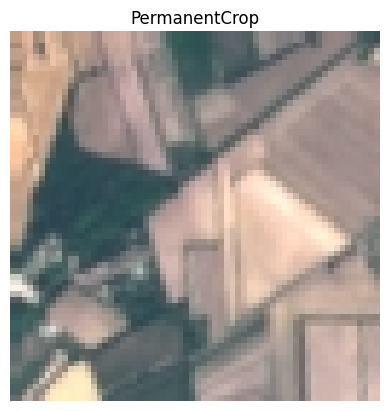

In [ ]:
from datasets import load_dataset, load_from_disk

DATASET_ID = 'timm/eurosat-rgb'
SAVED_DATASET = DATA_DIR / 'eurosat_rgb_hf'

if (SAVED_DATASET / 'dataset_dict.json').exists():
    print('Using dataset already saved in Drive.')
    dataset = load_from_disk(str(SAVED_DATASET))
else:
    print('Downloading EuroSAT RGB dataset...')
    dataset = load_dataset(DATASET_ID)
    dataset.save_to_disk(str(SAVED_DATASET))
    print('Dataset downloaded and saved to:', SAVED_DATASET)

print(dataset)
print({split: len(dataset[split]) for split in dataset.keys()})
class_names = dataset['train'].features['label'].names
print('Classes:', class_names)
with open(PROJECT / 'class_names.json', 'w') as f:
    json.dump(class_names, f, indent=2)

sample = dataset['train'][0]
plt.imshow(sample['image'])
plt.title(class_names[int(sample['label'])])
plt.axis('off')
plt.show()


## Load the pretrained vision-language model and prepare QLoRA

The base model is downloaded from Hugging Face and cached by Transformers. The fine-tuned adapter is saved to Drive. This does not retrain a CNN.


In [ ]:
!pip uninstall -y bitsandbytes
!pip install -U --no-cache-dir bitsandbytes

import torch
import bitsandbytes as bnb

from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen2_5_VLForConditionalGeneration
)
from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training
)

# Check GPU
assert torch.cuda.is_available(), "Enable GPU in Colab!"

print("GPU:", torch.cuda.get_device_name(0))
print("CUDA:", torch.version.cuda)
print("BitsAndBytes:", bnb.__version__)

# Model
BASE_MODEL = "Qwen/Qwen2.5-VL-3B-Instruct"

processor = AutoProcessor.from_pretrained(BASE_MODEL)

# 4-bit quantization
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

# Load model
base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    BASE_MODEL,
    quantization_config=bnb_config,
    device_map="auto"
)

# Prepare for training
base_model = prepare_model_for_kbit_training(
    base_model,
    use_gradient_checkpointing=True
)

base_model.config.use_cache = False

# LoRA configuration
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj",
        "k_proj",
        "v_proj",
        "o_proj",
        "gate_proj",
        "up_proj",
        "down_proj"
    ]
)

# Apply LoRA
model = get_peft_model(base_model, lora_config)

model.print_trainable_parameters()

print("Qwen2.5-VL loaded successfully!")


Found existing installation: bitsandbytes 0.45.5
Uninstalling bitsandbytes-0.45.5:
  Successfully uninstalled bitsandbytes-0.45.5
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 43.1/43.1 MB 87.6 MB/s  0:00:00
GPU: Tesla T4
CUDA: 13.0
BitsAndBytes: 0.50.2


/usr/local/lib/python3.13/dist-packages/huggingface_hub/utils/_auth.py:94: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


preprocessor_config.json:   0%|          | 0.00/350 [00:00<?, ?B/s]

Using a slow image processor as `use_fast` is unset and a slow processor was saved with this model. `use_fast=True` will be the default behavior in v4.52, even if the model was saved with a slow processor. This will result in minor differences in outputs. You'll still be able to use a slow processor with `use_fast=False`.


tokenizer_config.json: 0.00B [00:00, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

... (7 outputs left out)

model-00001-of-00002.safetensors:   0%|          | 0.00/3.98G [00:00<?, ?B/s]

Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/216 [00:00<?, ?B/s]

trainable params: 18,576,384 || all params: 3,773,199,360 || trainable%: 0.4923
Qwen2.5-VL loaded successfully!


## Prepare image + answer examples

Each sample teaches the VLM to return exactly one of the EuroSAT class names. Batch size 1 is used to reduce GPU memory use.


In [ ]:
from torch.utils.data import Dataset, DataLoader
from PIL import Image
from tqdm.auto import tqdm

SYSTEM_TEXT = (
    'You are a satellite land-cover classification assistant. '
    'Classify the image into exactly one of these classes: ' +
    ', '.join(class_names) +
    '. Return only the exact class name.'
)

def build_messages(image, answer=None):
    msgs = [
        {'role':'system', 'content':SYSTEM_TEXT},
        {'role':'user', 'content':[
            {'type':'image', 'image':image},
            {'type':'text', 'text':'What land-cover class is shown in this satellite image?'}
        ]}
    ]
    if answer is not None:
        msgs.append({'role':'assistant', 'content':answer})
    return msgs

class EuroSATDataset(Dataset):
    def __init__(self, split):
        self.split = split
    def __len__(self):
        return len(self.split)
    def __getitem__(self, i):
        row = self.split[i]
        return row['image'].convert('RGB'), class_names[int(row['label'])]

def collate_one(items):
    image, answer = items[0]
    full_text = processor.apply_chat_template(
        build_messages(image, answer), tokenize=False, add_generation_prompt=False
    )
    prompt_text = processor.apply_chat_template(
        build_messages(image), tokenize=False, add_generation_prompt=True
    )
    full = processor(text=[full_text], images=[image], return_tensors='pt')
    prompt = processor(text=[prompt_text], images=[image], return_tensors='pt')
    labels = full['input_ids'].clone()
    labels[:, :prompt['input_ids'].shape[1]] = -100
    if processor.tokenizer.pad_token_id is not None:
        labels[labels == processor.tokenizer.pad_token_id] = -100
    full['labels'] = labels
    return full

train_ds = EuroSATDataset(dataset['train'])
val_ds = EuroSATDataset(dataset['validation'])
test_ds = EuroSATDataset(dataset['test'])
train_loader = DataLoader(train_ds, batch_size=1, shuffle=True, collate_fn=collate_one, num_workers=0)
print('Training images:', len(train_ds))


Training images: 16200


## Fine-tune with QLoRA

Full EuroSAT training can take many hours on a free Colab GPU. Keep `MAX_TRAIN_STEPS = 20` for a quick smoke test. Set it to `None` to use the complete training split for one epoch. Checkpoints are saved to Drive every 250 optimizer steps.


In [ ]:

import torch

# Disable gradient checkpointing on the entire model
for module in model.modules():
    if hasattr(module, "gradient_checkpointing"):
        module.gradient_checkpointing = False

# Disable it on the base model too
for module in base_model.modules():
    if hasattr(module, "gradient_checkpointing"):
        module.gradient_checkpointing = False

model.gradient_checkpointing_disable()
base_model.gradient_checkpointing_disable()

# Disable cache
model.config.use_cache = False
base_model.config.use_cache = False

# Enable input gradients for LoRA
if hasattr(model, "enable_input_require_grads"):
    model.enable_input_require_grads()

# Check trainable parameters
trainable = [
    p for p in model.parameters() if p.requires_grad
]

print("Gradient checkpointing disabled.")
print("Trainable parameters:", sum(p.numel() for p in trainable))

assert len(trainable) > 0, "No trainable LoRA parameters found!"

print("Model ready.")


Gradient checkpointing disabled.
Trainable parameters: 18576384
Model ready.


In [ ]:

import torch

# Disable checkpointing on every model component
for name, module in model.named_modules():

    if hasattr(module, "gradient_checkpointing"):
        module.gradient_checkpointing = False

    if hasattr(module, "use_reentrant"):
        module.use_reentrant = False

# Disable checkpointing on model and base model
for obj in [model, base_model]:

    if hasattr(obj, "gradient_checkpointing_disable"):
        obj.gradient_checkpointing_disable()

    if hasattr(obj, "config"):
        obj.config.use_cache = False

# Check all remaining checkpointing flags
active = []

for name, module in model.named_modules():
    if getattr(module, "gradient_checkpointing", False):
        active.append(name)

print("Active checkpointing modules:", active)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))

if active:
    print("Warning: Some checkpointing modules remain active.")
else:
    print("All visible checkpointing flags are disabled.")


Active checkpointing modules: []
Trainable parameters: 18576384
All visible checkpointing flags are disabled.


In [ ]:

import torch
import gc

from transformers import (
    AutoProcessor,
    BitsAndBytesConfig,
    Qwen2_5_VLForConditionalGeneration
)

from peft import (
    LoraConfig,
    get_peft_model,
    prepare_model_for_kbit_training
)

# Clear old model and optimizer
try:
    del optimizer
except NameError:
    pass

try:
    del model
except NameError:
    pass

try:
    del base_model
except NameError:
    pass

gc.collect()
torch.cuda.empty_cache()

# Model
BASE_MODEL = "Qwen/Qwen2.5-VL-3B-Instruct"

processor = AutoProcessor.from_pretrained(BASE_MODEL)

# Quantization
bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_compute_dtype=torch.float16,
    bnb_4bit_use_double_quant=True
)

# Reload base model
base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    BASE_MODEL,
    quantization_config=bnb_config,
    device_map="auto"
)

# Prepare without gradient checkpointing
base_model = prepare_model_for_kbit_training(
    base_model,
    use_gradient_checkpointing=False
)

base_model.config.use_cache = False

# Fresh LoRA configuration
lora_config = LoraConfig(
    r=8,
    lora_alpha=16,
    lora_dropout=0.05,
    bias="none",
    task_type="CAUSAL_LM",
    target_modules=[
        "q_proj", "k_proj", "v_proj", "o_proj",
        "gate_proj", "up_proj", "down_proj"
    ]
)

model = get_peft_model(base_model, lora_config)

model.print_trainable_parameters()

print("Fresh Qwen2.5-VL model loaded.")
print("Gradient checkpointing was not enabled.")


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

trainable params: 18,576,384 || all params: 3,773,199,360 || trainable%: 0.4923
Fresh Qwen2.5-VL model loaded.
Gradient checkpointing was not enabled.


In [ ]:
import torch

model.train()

optimizer = torch.optim.AdamW(
    [p for p in model.parameters() if p.requires_grad],
    lr=2e-4
)

# Get one batch from your existing training loader
batch = next(iter(train_loader))

# Move batch to GPU
batch = {
    k: v.to("cuda") if isinstance(v, torch.Tensor) else v
    for k, v in batch.items()
}

optimizer.zero_grad(set_to_none=True)

# Forward pass
outputs = model(**batch)
loss = outputs.loss

print("Loss:", loss.item())

# Backward pass
loss.backward()

# Update LoRA parameters
optimizer.step()

print("SUCCESS: Forward pass, backward pass and optimizer step completed!")

Loss: 1.4027687311172485
SUCCESS: Forward pass, backward pass and optimizer step completed!


In [ ]:
import os
import torch
from tqdm.auto import tqdm

# Settings
EPOCHS = 1
MAX_BATCHES = 500
GRAD_ACCUM = 4
SAVE_EVERY = 100

SAVE_DIR = "/content/drive/MyDrive/TerraNova_VLM/models/checkpoints"
os.makedirs(SAVE_DIR, exist_ok=True)

model.train()
optimizer.zero_grad(set_to_none=True)

global_step = 0
running_loss = 0.0

for epoch in range(EPOCHS):

    progress = tqdm(
        enumerate(train_loader),
        total=min(len(train_loader), MAX_BATCHES),
        desc=f"Epoch {epoch + 1}/{EPOCHS}"
    )

    for batch_idx, batch in progress:

        if batch_idx >= MAX_BATCHES:
            break

        batch = {
            k: v.to("cuda") if isinstance(v, torch.Tensor) else v
            for k, v in batch.items()
        }

        outputs = model(**batch)
        loss = outputs.loss

        running_loss += loss.item()

        (loss / GRAD_ACCUM).backward()

        if (batch_idx + 1) % GRAD_ACCUM == 0:
            torch.nn.utils.clip_grad_norm_(
                [p for p in model.parameters() if p.requires_grad],
                1.0
            )

            optimizer.step()
            optimizer.zero_grad(set_to_none=True)
            global_step += 1

            if global_step % SAVE_EVERY == 0:
                model.save_pretrained(
                    f"{SAVE_DIR}/checkpoint_{global_step}"
                )
                processor.save_pretrained(
                    f"{SAVE_DIR}/checkpoint_{global_step}"
                )

        progress.set_postfix(
            loss=f"{loss.item():.4f}",
            step=global_step
        )

    # Handle remaining accumulated gradients
    if (batch_idx + 1) % GRAD_ACCUM != 0:
        optimizer.step()
        optimizer.zero_grad(set_to_none=True)
        global_step += 1

# Save final adapter
FINAL_DIR = "/content/drive/MyDrive/TerraNova_VLM/models/qwen25vl_eurosat_qlora"

model.save_pretrained(FINAL_DIR)
processor.save_pretrained(FINAL_DIR)

print("Training completed!")
print("Final model saved at:", FINAL_DIR)
print("Optimizer steps:", global_step)

Epoch 1/1:   0%|          | 0/500 [00:00<?, ?it/s]

Training completed!
Final model saved at: /content/drive/MyDrive/TerraNova_VLM/models/qwen25vl_eurosat_qlora
Optimizer steps: 126


In [3]:
import torch
from pathlib import Path
from transformers import AutoProcessor, Qwen2_5_VLForConditionalGeneration
from peft import PeftModel

PROJECT_ROOT = Path.cwd()
MODEL_DIR = PROJECT_ROOT / "models"
BASE_MODEL = MODEL_DIR / "Qwen2.5-VL-3B-Instruct"
ADAPTER_PATH = MODEL_DIR / "qwen25vl_eurosat_qlora"

if not (BASE_MODEL / "config.json").exists():
    raise FileNotFoundError(f"Qwen base model not found: {BASE_MODEL}")
if not (ADAPTER_PATH / "adapter_model.safetensors").exists():
    raise FileNotFoundError(f"Trained satellite adapter not found: {ADAPTER_PATH}")

processor = AutoProcessor.from_pretrained(str(ADAPTER_PATH), use_fast=True)
base_model = Qwen2_5_VLForConditionalGeneration.from_pretrained(
    str(BASE_MODEL),
    torch_dtype=torch.float16,
    device_map={"": "cpu"},
    low_cpu_mem_usage=True,
)
model = PeftModel.from_pretrained(
    base_model,
    str(ADAPTER_PATH),
    device_map={"": "cpu"},
    low_cpu_mem_usage=False,
)
model.eval()
model.config.use_cache = True

print("TerraNova Qwen model and trained adapter loaded on CPU.")


Loading checkpoint shards:   0%|          | 0/2 [00:00<?, ?it/s]

: 

In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/TerraNova_VLM/dataset/eurosat_rgb_hf"

for root, dirs, files in os.walk(DATASET_PATH):
    level = root.replace(DATASET_PATH, "").count(os.sep)

    if level <= 2:
        print("  " * level + os.path.basename(root) + "/")

        if level == 2:
            print("  " * (level + 1) + f"{len(files)} files")

eurosat_rgb_hf/
  train/
  validation/
  test/


In [ ]:
from datasets import load_from_disk

DATASET_PATH = "/content/drive/MyDrive/TerraNova_VLM/dataset/eurosat_rgb_hf"

dataset = load_from_disk(DATASET_PATH)

print(dataset)
print("\nTrain:", len(dataset["train"]))
print("Validation:", len(dataset["validation"]))
print("Test:", len(dataset["test"]))

print("\nDataset features:")
print(dataset["test"].features)

print("\nFirst test example:")
print(dataset["test"][0])

DatasetDict({
    train: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 16200
    })
    validation: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
    test: Dataset({
        features: ['image', 'label', 'image_id'],
        num_rows: 5400
    })
})

Train: 16200
Validation: 5400
Test: 5400

Dataset features:
{'image': Image(mode=None, decode=True, id=None), 'label': ClassLabel(names=['AnnualCrop', 'Forest', 'HerbaceousVegetation', 'Highway', 'Industrial', 'Pasture', 'PermanentCrop', 'Residential', 'River', 'SeaLake'], id=None), 'image_id': Value(dtype='string', id=None)}

First test example:
{'image': <PIL.JpegImagePlugin.JpegImageFile image mode=RGB size=64x64 at 0x7FE3B18D23F0>, 'label': 4, 'image_id': 'Industrial_102'}


Testing TerraNova:   0%|          | 0/5400 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/transformers/generation/configuration_utils.py:631: UserWarning: `do_sample` is set to `False`. However, `temperature` is set to `1e-06` -- this flag is only used in sample-based generation modes. You should set `do_sample=True` or unset `temperature`.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/bitsandbytes/backends/cuda/ops.py:957: UserWarning: inner dimension (3420) is not aligned for fast kernel with blocksize=64, falling back to slower implementation.
  warn(



========== TERRANOVA TEST RESULTS ==========
Total test images: 5400
Valid predictions: 5400
Unrecognized predictions: 0
Accuracy on valid predictions: 59.98%

Classification Report:
                      precision    recall  f1-score   support

          AnnualCrop       0.36      0.96      0.52       596
              Forest       0.46      0.96      0.62       608
HerbaceousVegetation       0.55      0.47      0.51       573
             Highway       0.86      0.68      0.76       496
          Industrial       0.92      0.90      0.91       501
             Pasture       0.75      0.15      0.26       396
       PermanentCrop       0.00      0.00      0.00       538
         Residential       0.90      0.90      0.90       554
               River       0.89      0.73      0.80       529
             SeaLake       0.95      0.12      0.22       609

            accuracy                           0.60      5400
           macro avg       0.66      0.59      0.55      5400
        

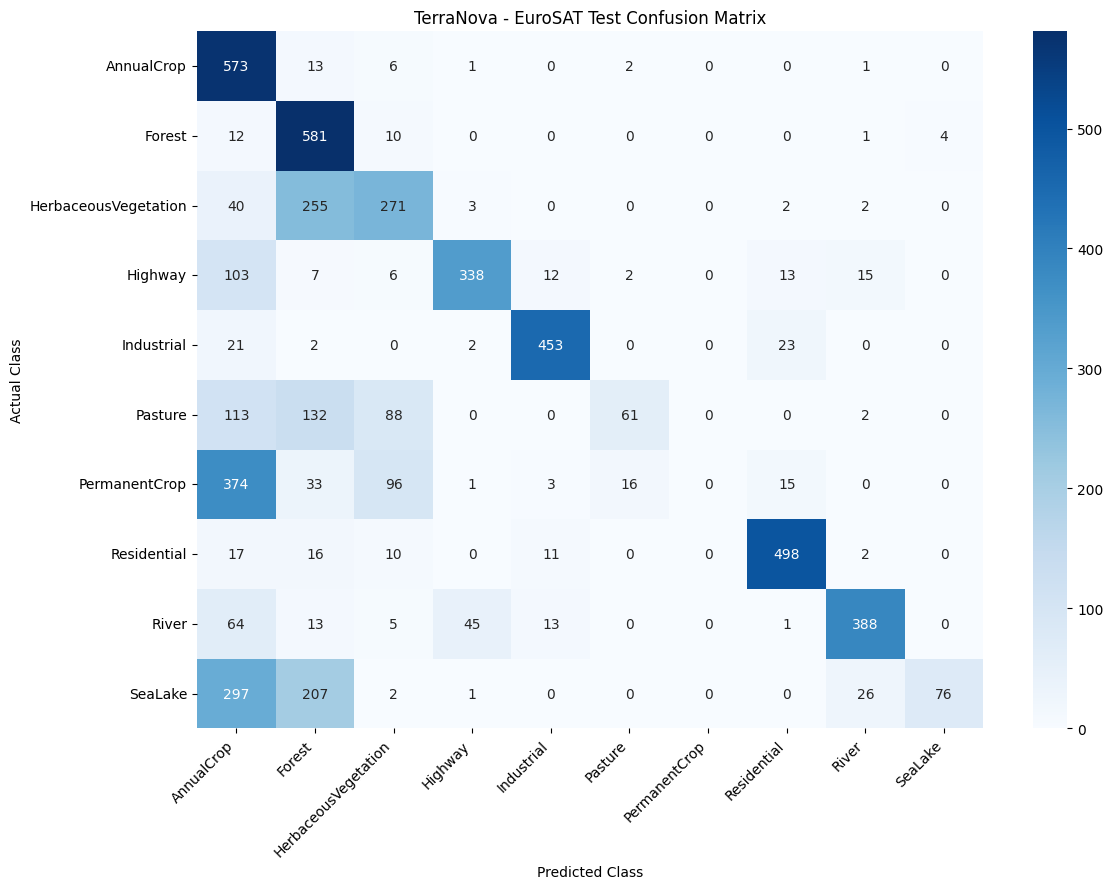


Predictions saved to: /content/drive/MyDrive/TerraNova_VLM/terranova_test_predictions.csv


In [ ]:
import torch
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from tqdm.auto import tqdm
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix
)

# Load test dataset
test_dataset = dataset["test"]

class_names = dataset["test"].features["label"].names

# Prediction function
def predict_satellite_image(image):

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image
                },
                {
                    "type": "text",
                    "text": (
                        "Classify this satellite image into exactly "
                        "one of these classes: "
                        + ", ".join(class_names)
                        + ". Return only the class name."
                    )
                }
            ]
        }
    ]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = processor(
        text=[prompt],
        images=[image],
        return_tensors="pt"
    )

    inputs = {
        k: v.to("cuda") if isinstance(v, torch.Tensor) else v
        for k, v in inputs.items()
    }

    with torch.inference_mode():
        generated_ids = model.generate(
            **inputs,
            max_new_tokens=20,
            do_sample=False
        )

    input_length = inputs["input_ids"].shape[1]

    generated_text = processor.batch_decode(
        generated_ids[:, input_length:],
        skip_special_tokens=True
    )[0].strip()

    # Match generated answer with valid class names
    answer = generated_text.lower()

    for name in class_names:
        if name.lower() in answer:
            return class_names.index(name)

    return -1


# Evaluate test dataset
y_true = []
y_pred = []

for i in tqdm(range(len(test_dataset)), desc="Testing TerraNova"):

    sample = test_dataset[i]

    actual_label = sample["label"]
    predicted_label = predict_satellite_image(sample["image"])

    y_true.append(actual_label)
    y_pred.append(predicted_label)


# Calculate metrics
valid_indices = [
    i for i, p in enumerate(y_pred) if p != -1
]

valid_true = [y_true[i] for i in valid_indices]
valid_pred = [y_pred[i] for i in valid_indices]

accuracy = accuracy_score(valid_true, valid_pred)

print("\n========== TERRANOVA TEST RESULTS ==========")
print("Total test images:", len(y_true))
print("Valid predictions:", len(valid_indices))
print("Unrecognized predictions:", len(y_true) - len(valid_indices))
print(f"Accuracy on valid predictions: {accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        y_true,
        y_pred,
        labels=list(range(len(class_names))),
        target_names=class_names,
        zero_division=0
    )
)

# Confusion matrix
cm = confusion_matrix(
    y_true,
    y_pred,
    labels=list(range(len(class_names)))
)

plt.figure(figsize=(12, 9))
sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("TerraNova - EuroSAT Test Confusion Matrix")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.xticks(rotation=45, ha="right")
plt.tight_layout()
plt.show()

# Save predictions
results = pd.DataFrame({
    "image_id": test_dataset["image_id"],
    "actual_label": [class_names[x] for x in y_true],
    "predicted_label": [
        class_names[x] if x != -1 else "Unrecognized"
        for x in y_pred
    ]
})

RESULT_PATH = (
    "/content/drive/MyDrive/TerraNova_VLM/"
    "terranova_test_predictions.csv"
)

results.to_csv(RESULT_PATH, index=False)

print("\nPredictions saved to:", RESULT_PATH)

Saving fore.jpeg to fore.jpeg

Uploaded image: fore.jpeg


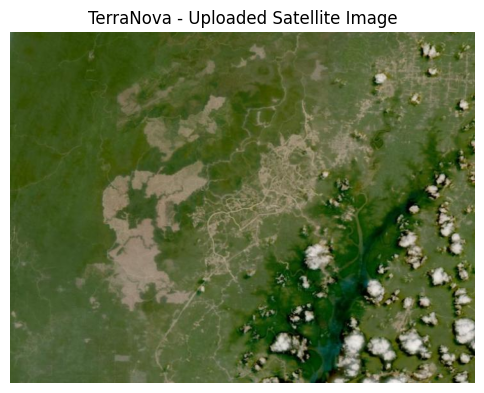


========== TERRANOVA PREDICTION ==========
Model response: Forest
Predicted class: Forest

Prediction saved successfully!
Image: /content/drive/MyDrive/TerraNova_VLM/new_predictions/uploaded_images/fore.jpeg
History: /content/drive/MyDrive/TerraNova_VLM/new_predictions/prediction_history.csv


In [ ]:
import os
import torch
import pandas as pd
import matplotlib.pyplot as plt

from PIL import Image
from google.colab import files
from datetime import datetime

# EuroSAT classes
class_names = [
    "AnnualCrop",
    "Forest",
    "HerbaceousVegetation",
    "Highway",
    "Industrial",
    "Pasture",
    "PermanentCrop",
    "Residential",
    "River",
    "SeaLake"
]

# Google Drive save locations
SAVE_DIR = "/content/drive/MyDrive/TerraNova_VLM/new_predictions"
IMAGE_DIR = os.path.join(SAVE_DIR, "uploaded_images")

os.makedirs(IMAGE_DIR, exist_ok=True)

CSV_PATH = os.path.join(SAVE_DIR, "prediction_history.csv")


def predict_terranova(image):

    messages = [
        {
            "role": "user",
            "content": [
                {
                    "type": "image",
                    "image": image
                },
                {
                    "type": "text",
                    "text": (
                        "Analyze this satellite image and identify its "
                        "dominant land-cover class. Choose exactly one "
                        "class from this list: "
                        + ", ".join(class_names)
                        + ". Return only the class name."
                    )
                }
            ]
        }
    ]

    prompt = processor.apply_chat_template(
        messages,
        tokenize=False,
        add_generation_prompt=True
    )

    inputs = processor(
        text=[prompt],
        images=[image],
        return_tensors="pt"
    )

    inputs = {
        k: v.to("cuda") if isinstance(v, torch.Tensor) else v
        for k, v in inputs.items()
    }

    with torch.inference_mode():
        output = model.generate(
            **inputs,
            max_new_tokens=30,
            do_sample=False
        )

    input_length = inputs["input_ids"].shape[1]

    response = processor.batch_decode(
        output[:, input_length:],
        skip_special_tokens=True
    )[0].strip()

    # Match the response with a valid class
    predicted_class = None

    for name in class_names:
        if name.lower() in response.lower():
            predicted_class = name
            break

    return response, predicted_class


def save_prediction(image, filename, response, predicted_class):

    timestamp = datetime.now().strftime("%Y-%m-%d %H:%M:%S")

    # Save uploaded image
    image_path = os.path.join(IMAGE_DIR, filename)
    image.save(image_path)

    # Save prediction history
    new_record = pd.DataFrame([{
        "timestamp": timestamp,
        "image_name": filename,
        "predicted_class": predicted_class or "Unrecognized",
        "model_response": response,
        "saved_image": image_path
    }])

    if os.path.exists(CSV_PATH):
        old_records = pd.read_csv(CSV_PATH)
        all_records = pd.concat(
            [old_records, new_record],
            ignore_index=True
        )
    else:
        all_records = new_record

    all_records.to_csv(CSV_PATH, index=False)

    print("\nPrediction saved successfully!")
    print("Image:", image_path)
    print("History:", CSV_PATH)


# Upload image
uploaded = files.upload()

for filename in uploaded.keys():

    image = Image.open(filename).convert("RGB")

    print("\nUploaded image:", filename)

    # Display image
    plt.figure(figsize=(6, 6))
    plt.imshow(image)
    plt.axis("off")
    plt.title("TerraNova - Uploaded Satellite Image")
    plt.show()

    # Predict
    response, predicted_class = predict_terranova(image)

    print("\n========== TERRANOVA PREDICTION ==========")
    print("Model response:", response)

    if predicted_class:
        print("Predicted class:", predicted_class)
    else:
        print("Predicted class: Unable to identify a valid class")

    # Save image and prediction
    save_prediction(
        image,
        filename,
        response,
        predicted_class
    )

In [ ]:
import pandas as pd

CSV_PATH = (
    "/content/drive/MyDrive/TerraNova_VLM/"
    "new_predictions/prediction_history.csv"
)

history = pd.read_csv(CSV_PATH)

display(history)

,timestamp,image_name,predicted_class,model_response,saved_image
0,2026-10-30 15:47:40,sat (1).jpeg,Residential,Residential,/content/drive/MyDrive/TerraNova_VLM/new_predi...
1,2026-10-30 15:56:22,fore.jpeg,Forest,Forest,/content/drive/MyDrive/TerraNova_VLM/new_predi...


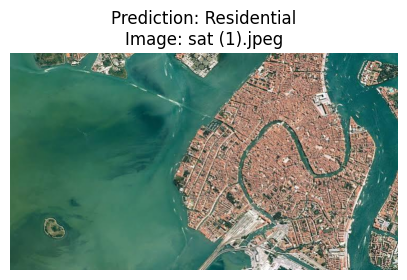

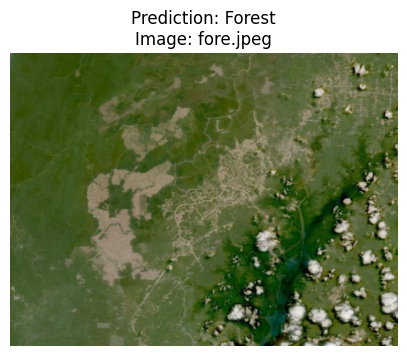

In [ ]:
import os
from PIL import Image
import matplotlib.pyplot as plt

IMAGE_DIR = (
    "/content/drive/MyDrive/TerraNova_VLM/"
    "new_predictions/uploaded_images"
)

history = pd.read_csv(
    "/content/drive/MyDrive/TerraNova_VLM/"
    "new_predictions/prediction_history.csv"
)

for _, row in history.iterrows():

    path = row["saved_image"]

    if os.path.exists(path):
        image = Image.open(path)

        plt.figure(figsize=(5, 4))
        plt.imshow(image)
        plt.title(
            f"Prediction: {row['predicted_class']}\n"
            f"Image: {row['image_name']}"
        )
        plt.axis("off")
        plt.show()

## Publish the trained adapter to Hugging Face

Run this section after training has saved the adapter to Google Drive. It creates a public model repository and uploads the adapter, tokenizer, and processor files. `notebook_login()` opens the Hugging Face sign-in flow; never paste an access token into a notebook cell or commit one to GitHub.

The Qwen base model is distributed under its research license. Before publishing this adapter, the upload cell includes the upstream `LICENSE` and required `NOTICE` attribution. If the repository already exists as private, make it public in Hugging Face settings before deploying without a token.

In [ ]:
%pip -q install huggingface_hub

from pathlib import Path
import shutil

from huggingface_hub import create_repo, hf_hub_download, notebook_login, upload_folder

adapter_dir = Path("/content/drive/MyDrive/TerraNova_VLM/models/qwen25vl_eurosat_qlora")
adapter_weights = (adapter_dir / "adapter_model.safetensors", adapter_dir / "adapter_model.bin")
if not adapter_dir.is_dir() or not any(path.is_file() for path in adapter_weights):
    raise FileNotFoundError(
        f"Trained adapter not found in {adapter_dir}. Run the training/save cells first."
    )

base_model_id = "Qwen/Qwen2.5-VL-3B-Instruct"
license_path = hf_hub_download(repo_id=base_model_id, filename="LICENSE")
shutil.copy2(license_path, adapter_dir / "LICENSE")
(adapter_dir / "NOTICE").write_text(
    "Qwen is licensed under the Qwen RESEARCH LICENSE AGREEMENT, "
    "Copyright (c) Alibaba Cloud. All Rights Reserved.\n",
    encoding="utf-8",
)
(adapter_dir / "README.md").write_text(
    "---\n"
    "base_model:\n"
    "- Qwen/Qwen2.5-VL-3B-Instruct\n"
    "library_name: peft\n"
    "pipeline_tag: image-text-to-text\n"
    "tags:\n"
    "- qwen\n"
    "- qwen2.5-vl\n"
    "- eurosat\n"
    "- satellite-imagery\n"
    "license: other\n"
    "license_name: qwen-research\n"
    "license_link: https://huggingface.co/Qwen/Qwen2.5-VL-3B-Instruct/blob/main/LICENSE\n"
    "---\n\n"
    "# TerraNova EuroSAT LoRA Adapter\n\n"
    "> Built with Qwen.\n\n"
    "A QLoRA adapter fine-tuned from Qwen2.5-VL-3B-Instruct for EuroSAT RGB "
    "satellite land-cover classification. This adapter is a model interpretation "
    "and is not verified ground truth.\n\n"
    "## License and attribution\n\n"
    "This adapter is based on Qwen2.5-VL and is provided subject to the included "
    "Qwen Research License and NOTICE. The Qwen license limits use to "
    "non-commercial purposes unless a separate license is obtained. Review the "
    "license before using or redistributing this adapter.\n",
    encoding="utf-8",
)

notebook_login()
repo_id = "BK0822/teranova"
create_repo(repo_id, repo_type="model", private=False, exist_ok=True)
upload_folder(
    folder_path=str(adapter_dir),
    repo_id=repo_id,
    repo_type="model",
)
print(f"TerraNova adapter uploaded to https://huggingface.co/{repo_id}")

In [1]:
%pip -q install "gradio>=5,<6"

import tempfile
from pathlib import Path
import gradio as gr
from PIL import Image

if "model" not in globals() or "processor" not in globals():
    raise RuntimeError(
        "Load the trained TerraNova adapter first by running the model-loading cell. "
        "This app uses the existing Colab model and Google Drive adapter."
    )
if not torch.cuda.is_available():
    raise RuntimeError("A CUDA-enabled Colab GPU is required to run the loaded model.")

app_classes = [
    "AnnualCrop", "Forest", "HerbaceousVegetation", "Highway", "Industrial",
    "Pasture", "PermanentCrop", "Residential", "River", "SeaLake"
]

language_choices = [
    ("English", "en-US"), ("Arabic", "ar-SA"), ("Bengali", "bn-BD"),
    ("Chinese (Simplified)", "zh-CN"), ("Chinese (Traditional)", "zh-TW"),
    ("Czech", "cs-CZ"), ("Danish", "da-DK"), ("Dutch", "nl-NL"),
    ("Filipino", "fil-PH"), ("Finnish", "fi-FI"), ("French", "fr-FR"),
    ("German", "de-DE"), ("Greek", "el-GR"), ("Gujarati", "gu-IN"),
    ("Hebrew", "he-IL"), ("Hindi", "hi-IN"), ("Hungarian", "hu-HU"),
    ("Indonesian", "id-ID"), ("Italian", "it-IT"), ("Japanese", "ja-JP"),
    ("Kannada", "kn-IN"), ("Korean", "ko-KR"), ("Malay", "ms-MY"),
    ("Malayalam", "ml-IN"), ("Marathi", "mr-IN"), ("Norwegian", "no-NO"),
    ("Persian", "fa-IR"), ("Polish", "pl-PL"), ("Portuguese", "pt-BR"),
    ("Punjabi", "pa-IN"), ("Romanian", "ro-RO"), ("Russian", "ru-RU"),
    ("Spanish", "es-ES"), ("Swahili", "sw-KE"), ("Swedish", "sv-SE"),
    ("Tamil", "ta-IN"), ("Telugu", "te-IN"), ("Thai", "th-TH"),
    ("Turkish", "tr-TR"), ("Ukrainian", "uk-UA"), ("Urdu", "ur-PK"),
    ("Vietnamese", "vi-VN")
]


def create_satellite_report(image, language):
    if image is None:
        raise gr.Error("Upload a satellite image to begin.")

    image = image.convert("RGB")
    prompt = (
        "Analyze this satellite image. First select its dominant land-cover class "
        f"from exactly this list: {', '.join(app_classes)}. Then write a concise, "
        f"useful report in the language with locale {language}. Include the exact "
        "class name, visible visual evidence, other clearly visible features, and "
        "caveats. Base the report only on visible image evidence. Do not infer an "
        "exact location, date, sensor, resolution, or facts not shown in the image. "
        "State that this is an image interpretation, not verified ground truth."
    )
    messages = [{
        "role": "user",
        "content": [
            {"type": "image", "image": image},
            {"type": "text", "text": prompt}
        ]
    }]
    formatted_prompt = processor.apply_chat_template(
        messages, tokenize=False, add_generation_prompt=True
    )
    inputs = processor(
        text=[formatted_prompt], images=[image], return_tensors="pt"
    )
    inputs = {
        key: value.to("cuda") if isinstance(value, torch.Tensor) else value
        for key, value in inputs.items()
    }
    with torch.inference_mode():
        generated = model.generate(
            **inputs, max_new_tokens=220, do_sample=False
        )
    prompt_length = inputs["input_ids"].shape[1]
    report_text = processor.batch_decode(
        generated[:, prompt_length:], skip_special_tokens=True
    )[0].strip()
    if not report_text:
        raise gr.Error("The model returned an empty report. Please try another image.")

    report_file = tempfile.NamedTemporaryFile(
        mode="w", encoding="utf-8", suffix=".txt", delete=False
    )
    with report_file:
        report_file.write(report_text)
    return report_text, report_file.name


satellite_css = """
.gradio-container { background: #10191b !important; color: #eef4ed !important; }
#mission-header { border-bottom: 1px solid #435355; padding: 18px 4px 20px; }
#mission-header h1 { color: #f0f5e9; font-size: 30px; margin: 0; }
#mission-header p { color: #b8c7c1; margin: 7px 0 0; }
#avatar-panel { min-height: 180px; display: flex; align-items: center; gap: 24px;
  padding: 16px; background: #192528; border: 1px solid #435355; border-radius: 6px; }
.earth { width: 116px; height: 116px; flex: 0 0 116px; border-radius: 50%;
  position: relative; background: radial-gradient(circle at 34% 30%, #b4e6cc 0 3%, transparent 4%),
  radial-gradient(ellipse at 68% 52%, #8ecba6 0 13%, transparent 14%),
  radial-gradient(ellipse at 36% 68%, #9ed5a7 0 12%, transparent 13%),
  radial-gradient(circle at 35% 35%, #4f9fa0, #24676d 53%, #143b46 78%);
  box-shadow: inset -12px -8px 18px #091c25, 0 0 24px #45b89d44; }
.earth:after { content: ''; position: absolute; inset: -10px -20px; border: 1px solid #a9d8c477;
  border-radius: 50%; transform: rotate(-24deg); }
.robot { width: 76px; height: 68px; position: relative; border: 2px solid #bed7ca;
  border-radius: 16px 16px 11px 11px; background: #27383a; }
.robot:before { content: ''; position: absolute; width: 2px; height: 13px; top: -15px; left: 36px;
  background: #bed7ca; }
.robot:after { content: ''; position: absolute; width: 9px; height: 9px; top: -19px; left: 33px;
  border-radius: 50%; background: #dcf074; }
.robot-eyes { display: flex; justify-content: center; gap: 14px; padding-top: 21px; }
.robot-eyes i { width: 9px; height: 9px; border-radius: 50%; background: #dcf074; }
.robot-mouth { width: 25px; height: 3px; margin: 11px auto; background: #83b9aa; }
.avatar-copy { color: #d7e3dc; line-height: 1.5; }
.avatar-copy strong { color: #dcf074; }
"""

with gr.Blocks(title="TerraNova | Satellite Image Intelligence", css=satellite_css) as app:
    gr.HTML("""
    <header id="mission-header">
      <h1>TERRANOVA <span style="color:#dcf074">/</span> IMAGE INTELLIGENCE</h1>
      <p>Satellite land-cover analysis · Qwen2.5-VL · EuroSAT classes</p>
    </header>
    """)
    with gr.Row():
        with gr.Column(scale=5):
            image_input = gr.Image(
                label="Satellite image", type="pil", sources=["upload"], height=360
            )
            language_input = gr.Dropdown(
                choices=language_choices, value="en-US", label="Report language",
                allow_custom_value=True
            )
            analyze_button = gr.Button("Analyze image", variant="primary")
        with gr.Column(scale=6):
            report_output = gr.Textbox(
                label="Image report", lines=13, max_lines=24, interactive=False,
                placeholder="Your model-generated report will appear here.",
                elem_id="report-output"
            )
            with gr.Row():
                speak_button = gr.Button("Speak report", elem_id="speak-report")
                download_output = gr.DownloadButton("Download .txt report")
            gr.HTML("""
            <section id="avatar-panel" aria-label="TerraNova speaking assistant">
              <div class="earth" aria-hidden="true"></div>
              <div>
                <div class="robot" aria-hidden="true">
                  <div class="robot-eyes"><i></i><i></i></div>
                  <div class="robot-mouth"></div>
                </div>
              </div>
              <div class="avatar-copy"><strong>TerraNova voice assistant</strong><br>
                Reports are spoken using a matching voice available in your browser.
              </div>
            </section>
            """)
    gr.Markdown(
        "Reports are model interpretations, not verified ground truth. "
        "For custom languages, enter a browser locale such as `sw-KE`. "
        "Speech depends on voices installed on your device."
    )

    analyze_button.click(
        fn=create_satellite_report,
        inputs=[image_input, language_input],
        outputs=[report_output, download_output]
    )
    speak_button.click(
        fn=None,
        inputs=[report_output, language_input],
        outputs=[],
        js="""(text, locale) => {
          if (!text || !window.speechSynthesis) return [];
          window.speechSynthesis.cancel();
          const utterance = new SpeechSynthesisUtterance(text);
          utterance.lang = locale || navigator.language || 'en-US';
          const voices = window.speechSynthesis.getVoices();
          const prefix = utterance.lang.toLowerCase().split('-')[0];
          const voice = voices.find(item => item.lang.toLowerCase() === utterance.lang.toLowerCase())
            || voices.find(item => item.lang.toLowerCase().startsWith(prefix));
          if (voice) utterance.voice = voice;
          window.speechSynthesis.speak(utterance);
          return [];
        }"""
    )

print("Starting TerraNova. A temporary share link lets you open the app in a browser.")
app.launch(share=True, show_error=True, quiet=True)


ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
google-genai 2.33.0 requires pydantic<3.0.0,>=2.12.5, but you have pydantic 2.12.3 which is incompatible.

[notice] A new release of pip is available: 26.2.2 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.


e:\PYTHON\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


RuntimeError: Load the trained TerraNova adapter first by running the model-loading cell. This app uses the existing Colab model and Google Drive adapter.